# 01_A - Preprocessing checks

Check the regional global signal, frequency content and recording duration in MA and DBS.
Each section contains a test, a plot and a short interpretation from the previous diagnostic run.
Run from the project directory; outputs go to `results/diagnostics`.


In [10]:
from pathlib import Path
import os
import sys

ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / 'src' / 'hoi_anesthesia').is_dir()
)
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import importlib
import json
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from src.hoi_anesthesia import diagnostics as dg

importlib.reload(dg)
MAT_PATHS = {
    'MA': Path(r'C:\CAMILO\Brain_Entropy\DATA\monkeys\data_ts_Anesthesia_Cleaned.mat'),
    'DBS': Path(r'C:\CAMILO\Brain_Entropy\DATA\monkeys\data_ts_DBS_CoCoMac_0.0025-0.05_Cleaned_Camilo_version.mat'),
}
OUT = Path('results') / 'diagnostics'
OUT.mkdir(parents=True, exist_ok=True)
DATASETS = ['MA', 'DBS']
ts = {ds: dg.load_timeseries(path, ds) for ds, path in MAT_PATHS.items()}
sns.set_theme(style='whitegrid', context='notebook')


## 1. Regional global signal

Measure each region's shared variance with the scan's mean z-scored regional signal.
Compare states to assess whether additional regional GSR needs testing in both datasets.


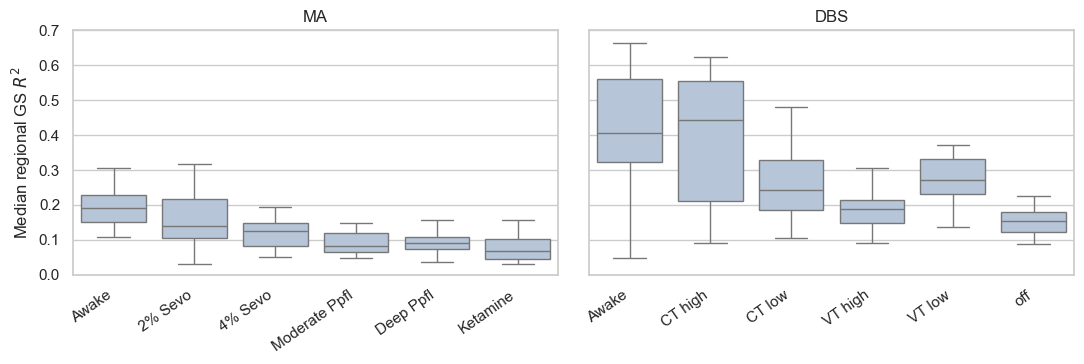

In [11]:
def regional_gs_r2(x):
    z = dg.zscore_regions(x)
    g = z.mean(axis=1)
    return np.median(((z * g[:, None]).mean(axis=0) / g.std()) ** 2)


gs = pd.DataFrame([
    {
        'dataset': ds, 'state': state, 'scan': i,
        'gs_r2': regional_gs_r2(x),
    }
    for ds in DATASETS for state, scans in ts[ds].items()
    for i, x in enumerate(scans)
])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, ds in zip(axes, DATASETS):
    states = list(ts[ds])
    sns.boxplot(
        data=gs[gs.dataset == ds], x='state', y='gs_r2',
        order=states, showfliers=False, color='lightsteelblue', ax=ax,
    )
    ax.set_xticks(
        range(len(states)), [dg.PRETTY_LABELS[s] for s in states],
        rotation=35, ha='right',
    )
    ax.set(title=ds, xlabel='', ylabel='Median regional GS $R^2$')
    ax.set_ylim(0,0.7)

fig.tight_layout()
fig.savefig(OUT / '01_A_fig_global_signal.png', dpi=150)
plt.show()


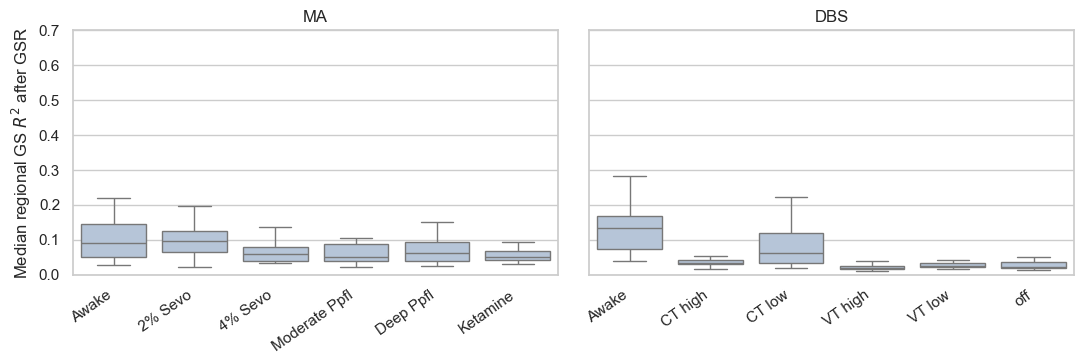

In [12]:
gs_after = pd.DataFrame([
    {
        'dataset': ds, 'state': state, 'scan': i,
        'gs_r2': regional_gs_r2(dg.regress_global_signal(x)),
    }
    for ds in DATASETS for state, scans in ts[ds].items()
    for i, x in enumerate(scans)
])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, ds in zip(axes, DATASETS):
    states = list(ts[ds])
    sns.boxplot(
        data=gs_after[gs_after.dataset == ds], x='state', y='gs_r2',
        order=states, showfliers=False, color='lightsteelblue', ax=ax,
    )
    ax.set_xticks(
        range(len(states)), [dg.PRETTY_LABELS[s] for s in states],
        rotation=35, ha='right',
    )
    ax.set(title=ds, xlabel='', ylabel='Median regional GS $R^2$ after GSR')
    ax.set_ylim(0,0.7)
fig.tight_layout()
fig.savefig(OUT / '01_A_fig_global_signal_after_gsr.png', dpi=150)
plt.show()


**Result.** Both datasets retain a regional global component, stronger overall in DBS and variable
across states. Test the same additional regional GSR in both; this does not establish that the
removed component is purely nuisance.


## 2. Frequency content

Compare normalised spectra, resolving the narrow notch at native frequency resolution.
Check the existing 0.0025-0.05 Hz band and power above the Nyquist frequency after DBS decimation.


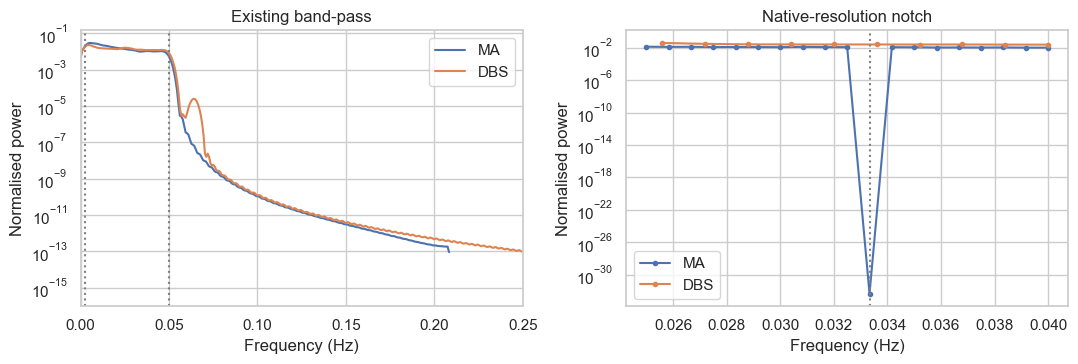

,out_of_band_power,above_decimated_nyquist
dataset,,
DBS,1.58e-04,2.06e-11
MA,1.15e-06,2.05e-12


In [13]:
spectra, spectral_rows = {}, []
for ds in DATASETS:
    tr = dg.TR_SECONDS[ds]
    welch, native = [], []
    for state, scans in ts[ds].items():
        for i, x in enumerate(scans):
            f, p = dg.welch_psd(x, tr)
            fp, pp = dg.periodogram_psd(x, tr)
            welch.append(p)
            native.append(pp)
            spectral_rows.append({
                'dataset': ds, 'state': state, 'scan': i,
                'out_of_band_power': dg.band_fraction(f, p, 0.06, np.inf),
                'above_decimated_nyquist': dg.band_fraction(f, p, 0.2, np.inf),
                'notch_depth': dg.notch_depth(fp, pp),
                'notch_hz': dg.notch_frequency(fp, pp),
            })
    spectra[ds] = (f, np.median(welch, axis=0), fp, np.median(native, axis=0))
spectral = pd.DataFrame(spectral_rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ds, (f, p, fp, pp) in spectra.items():
    axes[0].semilogy(f, p, label=ds)
    mask = (fp >= 0.025) & (fp <= 0.04)
    axes[1].semilogy(fp[mask], pp[mask], 'o-', markersize=3, label=ds)
for hz in (0.0025, 0.05):
    axes[0].axvline(hz, color='grey', linestyle=':')
axes[0].set(xlim=(0, 0.25), xlabel='Frequency (Hz)', ylabel='Normalised power',
            title='Existing band-pass')
axes[1].axvline(1 / 30, color='grey', linestyle=':')
axes[1].set(xlabel='Frequency (Hz)', ylabel='Normalised power',
            title='Native-resolution notch')
for ax in axes:
    ax.legend()
fig.tight_layout()
fig.savefig(OUT / '01_A_fig_spectra.png', dpi=150)
plt.show()
display(spectral.groupby('dataset')[
    ['out_of_band_power', 'above_decimated_nyquist']
].median().style.format('{:.2e}'))


**Result.** Both datasets already have negligible out-of-band power; only MA has the narrow
0.0333-Hz notch. Retain the band-pass and test that notch in DBS. Existing filtering leaves
negligible power above the decimated DBS Nyquist frequency, so no additional anti-alias filter is indicated.


## 3. Duration and covariance reliability

Compare regional effective sample size before and after approximate duration matching.
Compare correlation matrices from separate approximately 300-s segments to assess remaining reliability differences.


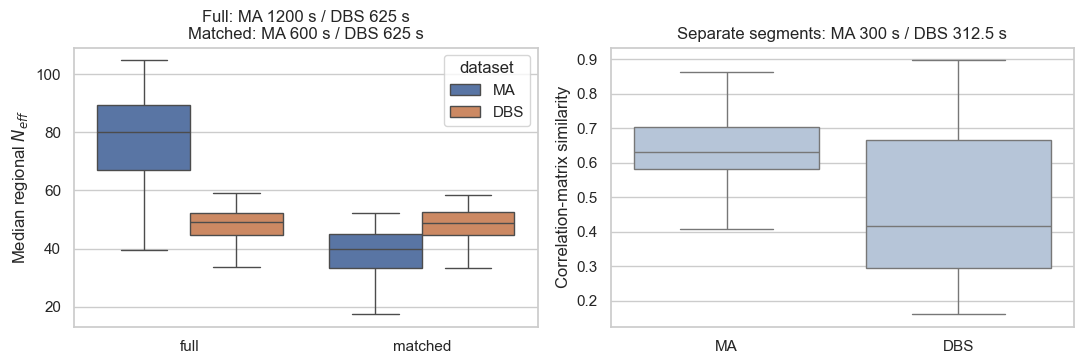

934

In [14]:
def segment_correlation(x):
    return dg.upper(dg.cov_to_corr(dg.gc_covariances(x[None])[0]))


temporal_rows = []
for ds in DATASETS:
    for state, scans in ts[ds].items():
        for i, x in enumerate(scans):
            matched = dg.temporal_harmonise(x, ds)
            segments = np.array_split(x, 4 if ds == 'MA' else 2)
            similarities = [
                np.corrcoef(
                    segment_correlation(segments[j]),
                    segment_correlation(segments[j + 1]),
                )[0, 1]
                for j in range(0, len(segments), 2)
            ]
            temporal_rows.append({
                'dataset': ds, 'state': state, 'scan': i,
                'full': np.median(dg.effective_sample_size(x)),
                'matched': np.median(dg.effective_sample_size(matched)),
                'reliability': np.mean(similarities),
            })
temporal = pd.DataFrame(temporal_rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.boxplot(
    data=temporal.melt(
        id_vars='dataset', value_vars=['full', 'matched'],
        var_name='duration', value_name='neff',
    ),
    x='duration', y='neff', hue='dataset', showfliers=False, ax=axes[0],
)
axes[0].set(
    xlabel='', ylabel='Median regional $N_{eff}$',
    title='Full: MA 1200 s / DBS 625 s\nMatched: MA 600 s / DBS 625 s',
)
sns.boxplot(
    data=temporal, x='dataset', y='reliability',
    showfliers=False, color='lightsteelblue', ax=axes[1],
)
axes[1].set(
    xlabel='', ylabel='Correlation-matrix similarity',
    title='Separate segments: MA 300 s / DBS 312.5 s',
)
fig.tight_layout()
fig.savefig(OUT / '01_A_fig_duration.png', dpi=150)
plt.show()

gs.merge(spectral, on=['dataset', 'state', 'scan']).merge(
    temporal, on=['dataset', 'state', 'scan'],
).to_csv(OUT / '01_A_scan_metrics.csv', index=False)
summary = {
    'generated': datetime.now().isoformat(timespec='seconds'),
    'global_signal_r2': gs.groupby('dataset').gs_r2.median().to_dict(),
    'spectra': spectral.groupby('dataset').median(numeric_only=True).to_dict(),
    'duration': temporal.groupby('dataset').median(numeric_only=True).to_dict(),
}
(OUT / '01_A_summary.json').write_text(
    json.dumps(dg.to_builtin(summary), indent=2), encoding='utf-8',
)


**Result.** Full MA scans have more effective samples. Approximate duration matching reduces
this difference, but DBS covariance reliability remains lower at comparable segment lengths.
Test duration sensitivity in Phase 2; matching does not make the acquisitions equivalent.
